# Group 20 — Part B: Exploratory Data Analysis & Feature Engineering
**Task:** predict taxi trip duration (minutes) at pickup — regression.
**Input:** Member A's cleaned NYC TLC Yellow Taxi data (contract in `Group20_ETA_A/handoff.py`).
**Output:** feature matrices for the models (Parts C/D), EDA figures, leakage checks and a task-parallel encoding benchmark.

| Setting | How to set |
|---|---|
| `ETA_DATA` | A's sample Parquet (local development) **or** A's Rockhill run directory containing `cleaned_parts/` (full data) |
| `ETA_WORKERS` | worker counts to benchmark, e.g. `1 2 4` |
| `ETA_VAL_START`, `ETA_TEST_START` | chronological split boundaries |
| `ETA_RUN` | output folder name under `outputs/` |

On Rockhill: `bash run_rockhill_b.sh` (uses the `cs4207` partition).

In [1]:
import os, sys, json, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

A_DIR = Path(os.environ.get('ETA_A_DIR', '../Group20_ETA_A'))
DATA = os.environ.get('ETA_DATA', str(A_DIR / 'outputs/local_jan2026/sample_100k.parquet'))
WORKERS = [int(w) for w in os.environ.get('ETA_WORKERS', '1 2 4').split()]
VAL_START = os.environ.get('ETA_VAL_START', '2026-01-22')
TEST_START = os.environ.get('ETA_TEST_START', '2026-01-27')
RUN = os.environ.get('ETA_RUN', 'local_sample')
OUT = Path('outputs') / RUN; FIG = OUT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(A_DIR)); sys.path.insert(0, '.')
from handoff import chronological_split, inputs_and_target            # A's contract
from b_features import (FeatureBuilder, load_cleaned, stateless_features, benchmark,
                        fingerprint, FORBIDDEN_INPUTS, TIME_BANDS, AIRPORT_ZONES)

INK, INK2, GRID, BLUE = '#191919', '#666666', '#e7e7e7', '#257de0'
BLUES = ['#cce3fd', '#9dc8f7', '#6aabf1', '#338ced', '#2370cd', '#1757ac', '#0e3d7e']
def style(ax, title, xlabel='', ylabel='', grid='y'):
    ax.set_title(title, loc='left', fontsize=13, color=INK, pad=10)
    ax.set_xlabel(xlabel, color=INK2); ax.set_ylabel(ylabel, color=INK2)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
    for s in ['left', 'bottom']: ax.spines[s].set_color('#c2c2c2')
    ax.tick_params(colors=INK2); ax.set_axisbelow(True)
    if grid: ax.grid(axis=grid, color=GRID, linewidth=0.8)
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f'{name}.png', dpi=200); plt.close(fig)
    display(Image(str(FIG / f'{name}.png'), width=850))

summary = {'data_source': DATA, 'run': RUN,
           'environment': {'python': platform.python_version(), 'platform': platform.platform(),
                           'cpus_visible': os.cpu_count(), 'slurm_cpus': os.environ.get('SLURM_CPUS_PER_TASK'),
                           'pandas': pd.__version__, 'numpy': np.__version__}}
summary['environment']

{'python': '3.13.18',
 'platform': 'Linux-6.18.44-fc-v880-x86_64-with-glibc2.39',
 'cpus_visible': 2,
 'slurm_cpus': None,
 'pandas': '3.0.5',
 'numpy': '2.5.3'}

## 1. Load and split chronologically
Splits use pickup time, never random rows, so the model is always evaluated on trips that happen *after* its training data.

In [2]:
df = load_cleaned(DATA)
train, val, test = chronological_split(df, VAL_START, TEST_START)
Xtr, ytr = inputs_and_target(train); Xva, yva = inputs_and_target(val); Xte, yte = inputs_and_target(test)
summary['rows'] = {'all': len(df), 'train': len(train), 'validation': len(val), 'test': len(test)}
summary['split'] = {'train': f"{train.pickup_datetime.min()} to {train.pickup_datetime.max()}",
                    'validation_start': VAL_START, 'test_start': TEST_START}
print('Raw model inputs:', list(Xtr.columns))
pd.DataFrame(summary['rows'], index=['rows'])

Raw model inputs: ['pickup_datetime', 'pickup_zone', 'dropoff_zone', 'passenger_count', 'passenger_count_missing']


,all,train,validation,test
rows,100000,67074,14415,18511


## 2. Exploratory data analysis (training period only)
All EDA uses the training split, so nothing we learn about the data comes from the validation or test periods.

### 2.1 Target distribution

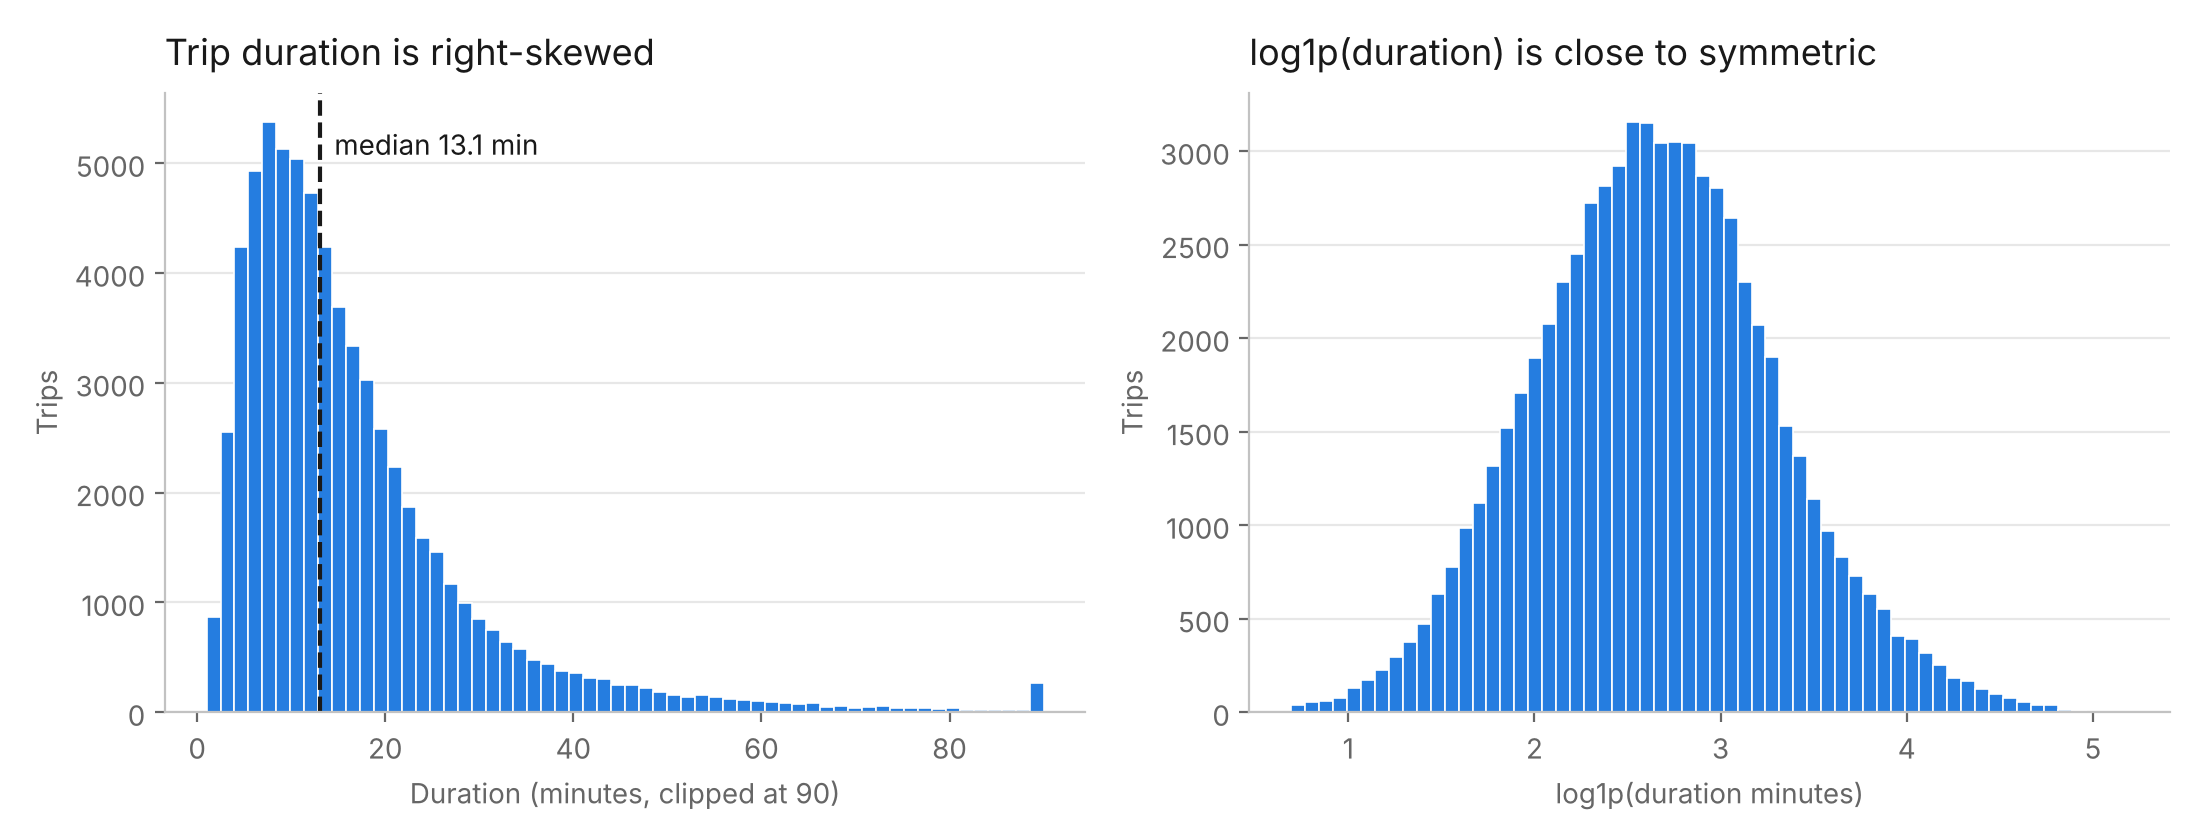

{'count': 67074.0,
 'mean': 16.67,
 'std': 13.49,
 'min': 1.0,
 '25%': 8.1,
 '50%': 13.08,
 '75%': 20.63,
 '95%': 42.22,
 'max': 178.38,
 'skew': 2.66}

In [3]:
summary['target_train'] = {k: round(float(v), 2) for k, v in ytr.describe(percentiles=[.25, .5, .75, .95]).items()}
summary['target_train']['skew'] = round(float(ytr.skew()), 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(ytr.clip(upper=90), bins=60, color=BLUE, edgecolor='white', linewidth=0.6)
axes[0].axvline(ytr.median(), color=INK, linewidth=1.5, linestyle='--')
axes[0].text(ytr.median() + 1.5, axes[0].get_ylim()[1] * 0.9, f'median {ytr.median():.1f} min', color=INK)
style(axes[0], 'Trip duration is right-skewed', 'Duration (minutes, clipped at 90)', 'Trips')
axes[1].hist(np.log1p(ytr), bins=60, color=BLUE, edgecolor='white', linewidth=0.6)
style(axes[1], 'log1p(duration) is close to symmetric', 'log1p(duration minutes)', 'Trips')
save(fig, 'B_duration_distribution')
summary['target_train']

**Finding:** the target has a long right tail. We therefore encode and model `log1p(duration)` and convert predictions back with `expm1`.

### 2.2 Time of day and day of week

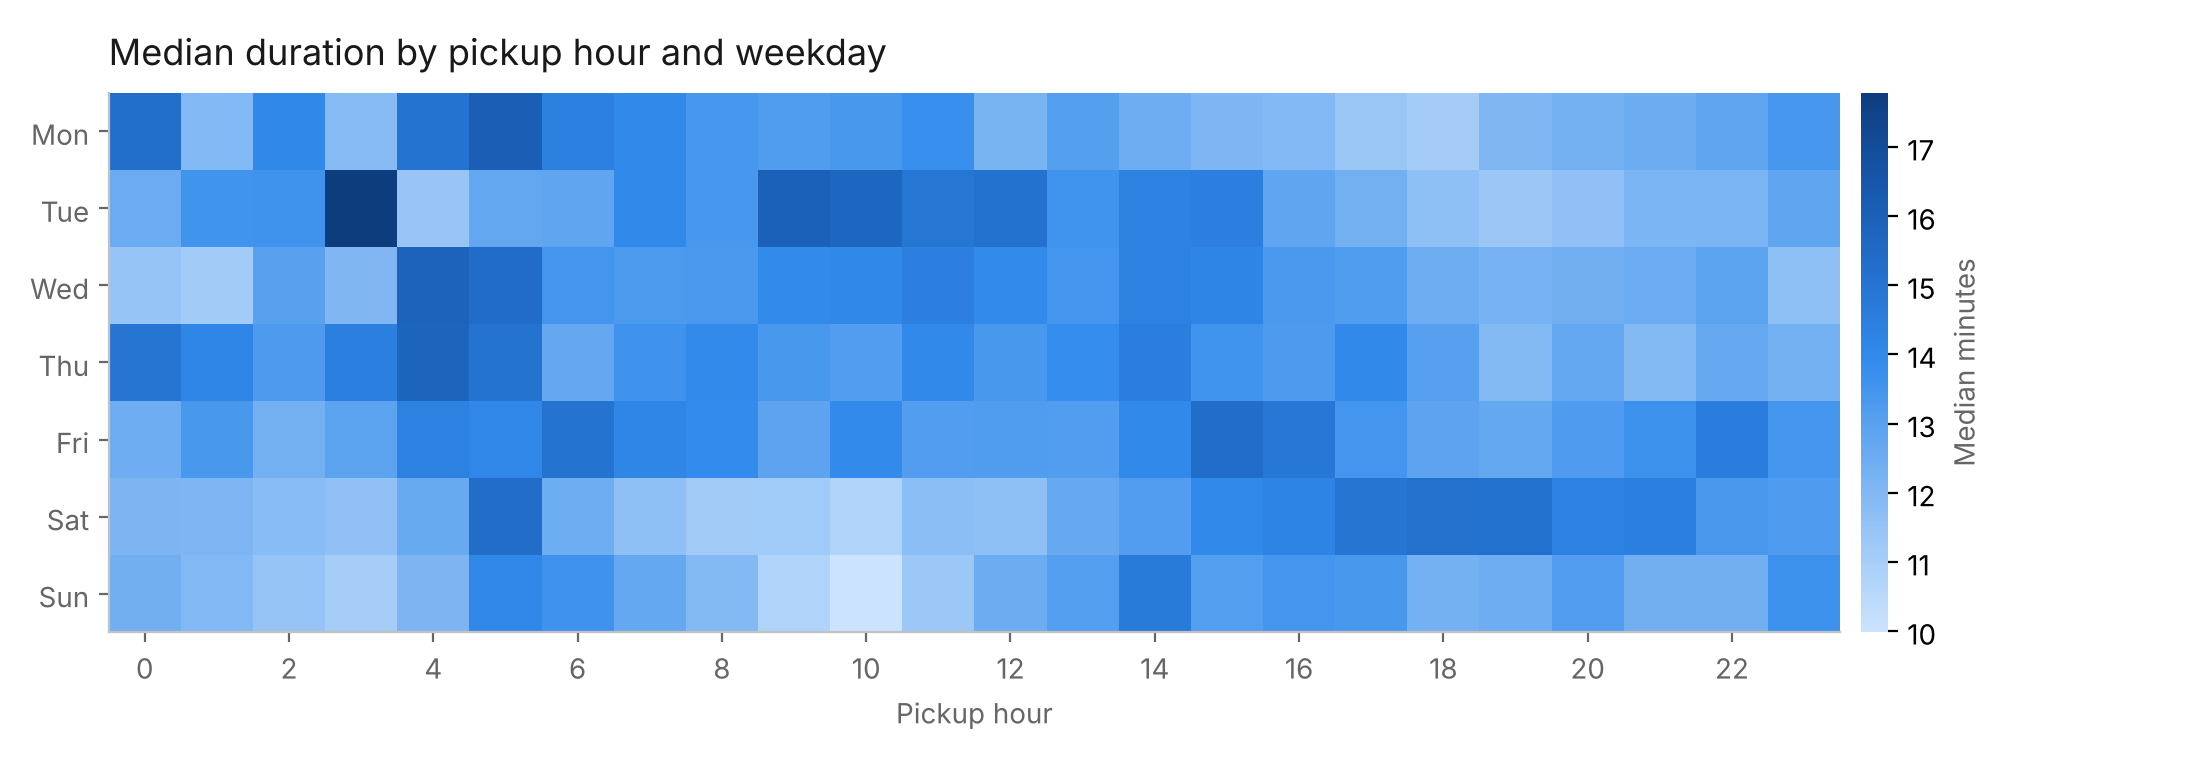

,median_minutes
afternoon_peak,12.95
evening,12.83
midday,13.35
morning_peak,13.33
night,12.70


In [4]:
s = stateless_features(Xtr).assign(y=ytr.values)
piv = s.pivot_table(index='day_of_week', columns='hour', values='y', aggfunc='median')
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(piv.values, aspect='auto', cmap=matplotlib.colors.LinearSegmentedColormap.from_list('b', BLUES))
ax.set_yticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']); ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
style(ax, 'Median duration by pickup hour and weekday', 'Pickup hour', grid=None)
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label('Median minutes', color=INK2); cb.outline.set_visible(False)
save(fig, 'B_hour_weekday_heatmap')
summary['hour_weekday_median_range'] = [round(float(piv.min().min()), 1), round(float(piv.max().max()), 1)]
summary['median_by_band_train'] = s.groupby('time_band')['y'].median().round(2).to_dict()
pd.DataFrame({'median_minutes': summary['median_by_band_train']})

### 2.3 Location: airports and same-zone trips

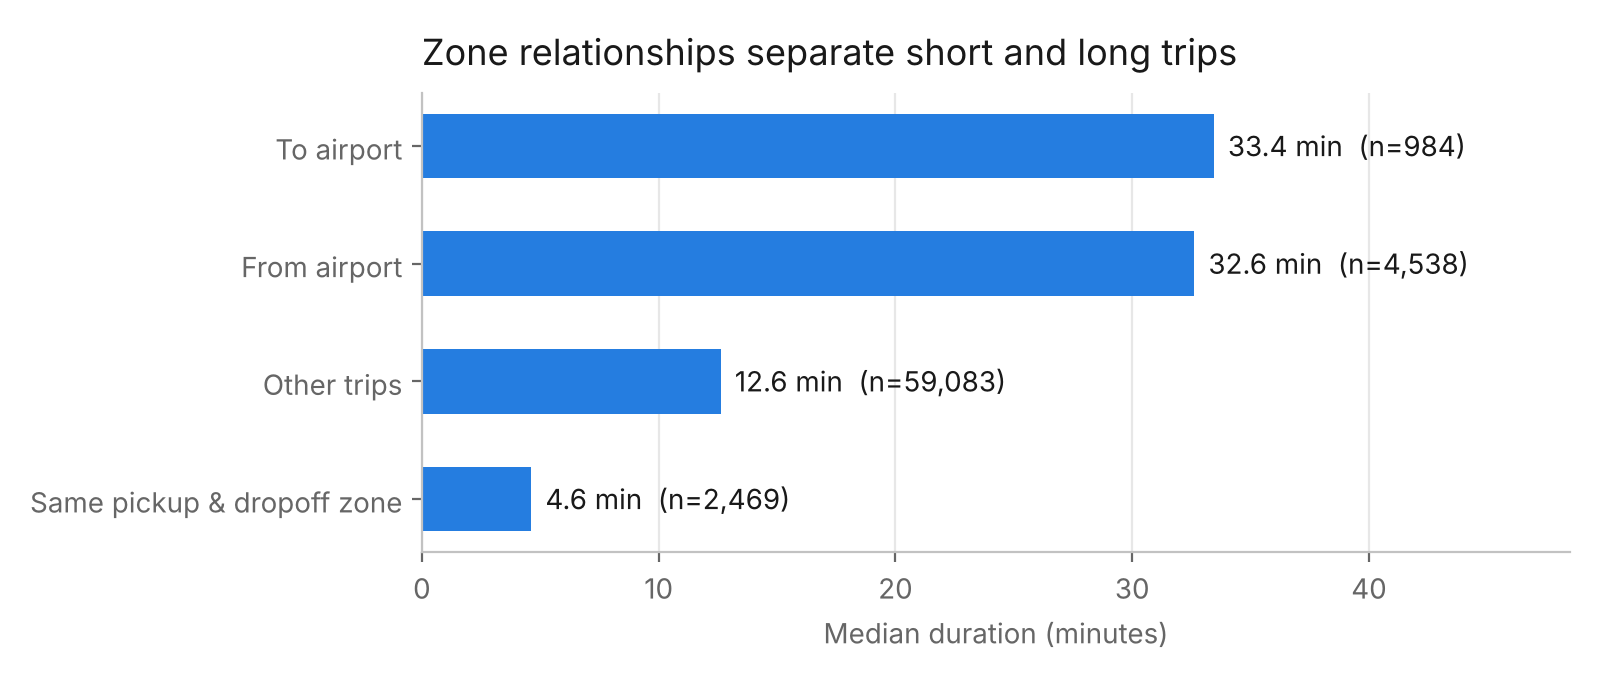

,median,count
group,,
Same pickup & dropoff zone,4.62,2469
Other trips,12.62,59083
From airport,32.62,4538
To airport,33.44,984


In [5]:
grp = np.select([s['same_zone'] == 1, s['dropoff_airport'] == 1, s['pickup_airport'] == 1],
                ['Same pickup & dropoff zone', 'To airport', 'From airport'], 'Other trips')
g = s.assign(group=grp).groupby('group')['y'].agg(['median', 'count']).sort_values('median')
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(g.index, g['median'], color=BLUE, height=0.55)
for i, (m, c) in enumerate(zip(g['median'], g['count'])):
    ax.text(m + 0.6, i, f'{m:.1f} min  (n={c:,})', va='center', color=INK, fontsize=10)
ax.set_xlim(0, g['median'].max() * 1.45)
style(ax, 'Zone relationships separate short and long trips', 'Median duration (minutes)', grid='x')
save(fig, 'B_trip_groups')
summary['trip_groups_train'] = g.round(2).reset_index().to_dict('records')
g.round(2)

**Findings:** location dominates. Airport trips take roughly 2.5× as long as other trips, and same-zone trips are very short. Time of day shifts the median by several minutes. This motivates zone-pair features combined with time features.

## 3. Feature engineering
| Group | Features | Fitted? |
|---|---|---|
| Calendar | hour, day of week, weekend, US holiday, day of month, cyclic sin/cos of time-of-day and weekday | no |
| Our peak definition | night 00–06, **morning peak 06–10**, midday 10–16, **afternoon peak 16–20**, evening 20–24 (+ `is_peak`) | no |
| Zone flags | pickup/dropoff at an airport (EWR 1, JFK 132, LGA 138), same pickup and dropoff zone | no |
| Target encodings | smoothed mean log-duration per pickup zone, dropoff zone, zone pair, zone pair × time band, pickup zone × hour, plus log counts (how reliable each encoding is) and a pair/zone blend for rare pairs | **train only** |
| Passenger | count (train-median imputation) + missing indicator | **train only** |

**Leakage control:** realised distance, fares, tips, payment type and dropoff time are *not* inputs; they are only known after the trip ends. Training rows get **5-fold out-of-fold** encodings, so no row's encoding includes its own label. Validation and test rows use encodings fitted on the whole training split. Smoothing (m = 20) shrinks rare keys toward the prior.

In [6]:
fb = FeatureBuilder(n_jobs=max(WORKERS))
F_tr = fb.fit_transform(Xtr, ytr); F_va = fb.transform(Xva); F_te = fb.transform(Xte)

# leakage and integrity checks
for F in (F_tr, F_va, F_te):
    assert not FORBIDDEN_INPUTS.intersection(F.columns), 'leaky column present'
    assert not F.isna().any().any(), 'missing values in features'
    assert all(np.issubdtype(t, np.number) for t in F.dtypes)
assert list(F_tr.columns) == list(F_va.columns) == list(F_te.columns)
unseen = float((F_va['te_pair_count'] == 0).mean())
summary['n_features'] = F_tr.shape[1]; summary['feature_columns'] = list(F_tr.columns)
summary['validation_unseen_zone_pairs_pct'] = round(100 * unseen, 2)
print(f'{F_tr.shape[1]} features; {100*unseen:.1f}% of validation trips have a zone pair never seen in training')
F_tr.describe().T[['mean', 'std', 'min', 'max']].round(3)

33 features; 6.9% of validation trips have a zone pair never seen in training


,mean,std,min,max
hour,13.906,5.960,0.000,23.000
day_of_week,3.043,1.952,0.000,6.000
is_weekend,0.289,0.453,0.000,1.000
is_holiday,0.084,0.277,0.000,1.000
day_of_month,11.403,5.951,1.000,21.000
tod_sin,-0.277,0.639,-1.000,1.000
tod_cos,-0.123,0.707,-1.000,1.000
dow_sin,0.007,0.718,-0.975,0.975
dow_cos,-0.033,0.695,-0.901,1.000
is_peak,0.378,0.485,0.000,1.000


## 4. Feature signal on validation
A quick check of which features carry information about the target. This is **not a model**: the model results are in Parts C/D.

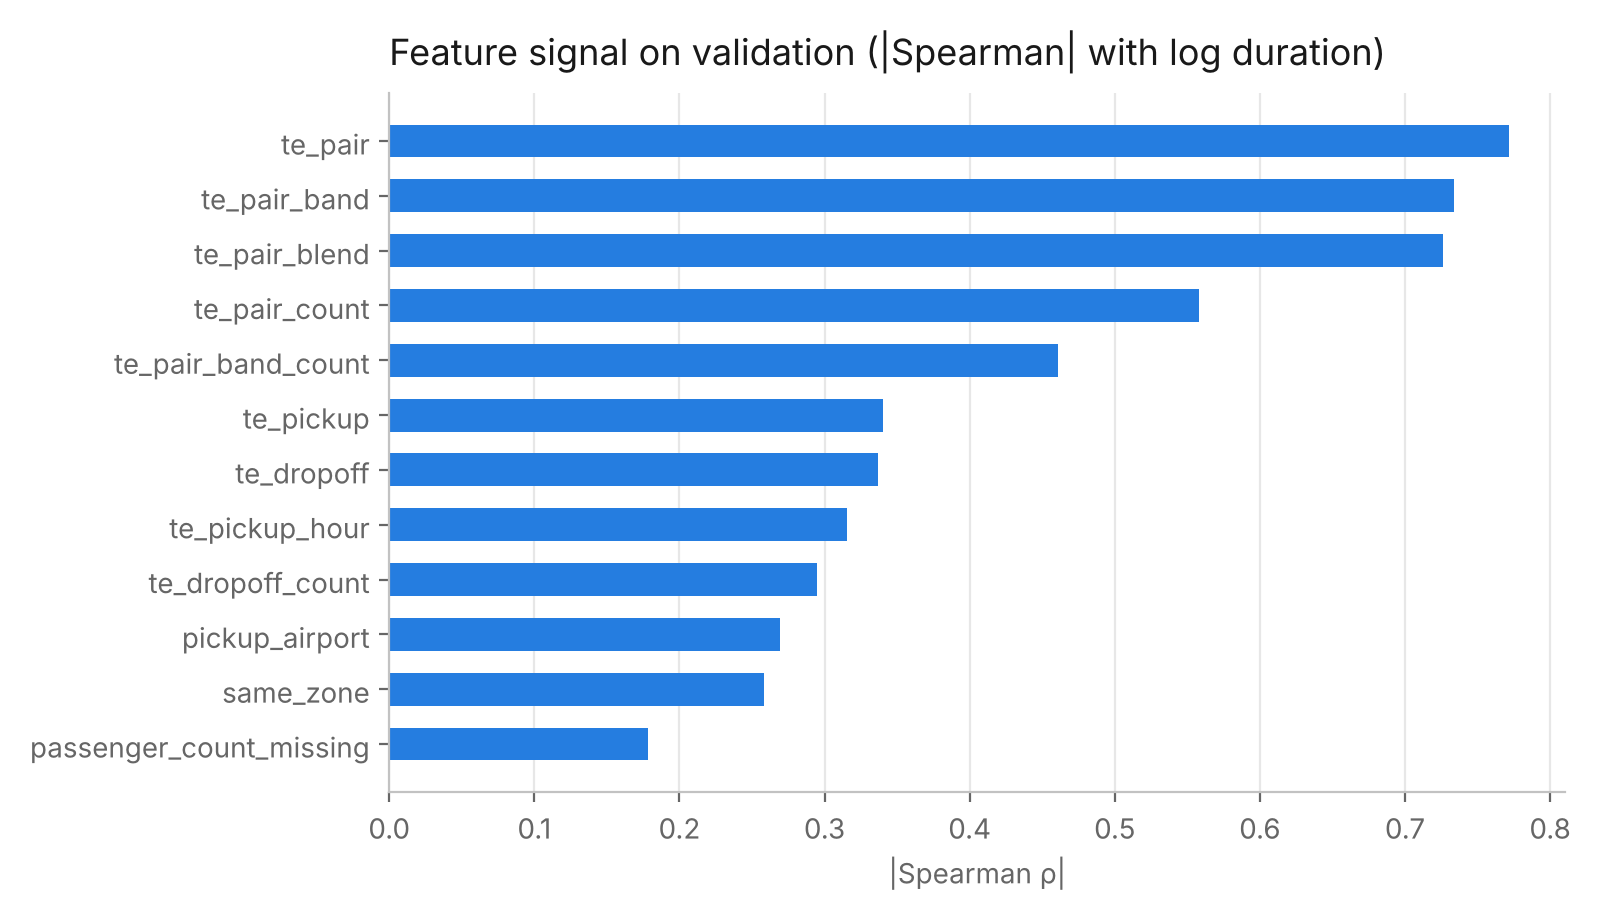

{'MAE_constant_train_median': 8.04,
 'MAE_zone_pair_lookup': 6.15,
 'reduction_pct': 23.6}

In [7]:
ylog = np.log1p(yva.values)
sig = pd.Series({c: abs(pd.Series(F_va[c].values).corr(pd.Series(ylog), method='spearman'))
                 for c in F_va.columns if F_va[c].nunique() > 1}).sort_values()
top = sig.tail(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
style(ax, 'Feature signal on validation (|Spearman| with log duration)', '|Spearman ρ|', grid='x')
save(fig, 'B_feature_signal')
mae_const = float(np.abs(yva.values - ytr.median()).mean())
mae_pair = float(np.abs(yva.values - np.expm1(F_va['te_pair'].values)).mean())
summary['validation_sanity'] = {'MAE_constant_train_median': round(mae_const, 2),
                                'MAE_zone_pair_lookup': round(mae_pair, 2),
                                'reduction_pct': round(100 * (1 - mae_pair / mae_const), 1)}
sig.sort_values(ascending=False).rename('|spearman|').to_csv(OUT / 'feature_signal_validation.csv')
summary['validation_sanity']

## 5. Task parallelism: feature extraction
Each (fold, table) encoding is an **independent task**: 5 folds × 5 tables for training, plus 5 tables for evaluation. Every task reads only its own fold's rows and writes only its own column block, so no task depends on another task's output. The tasks run in a `ProcessPoolExecutor`. Keys are integer-coded once in the parent, so each task ships only small integer arrays. Results are recombined **by task tag in a fixed column order**, never in completion order.

Benchmark: identical workload (`fit_transform` on train + `transform` on validation) for every worker count, one warm-up run, then 3 timed repeats. Outputs are hashed to prove they are identical.

In [8]:
bench = benchmark(Xtr, ytr, Xva, jobs=tuple(WORKERS), repeats=3)
summary['benchmark'] = bench.round(4).to_dict('records')
bench.to_csv(OUT / 'benchmark_features.csv', index=False)
bench.round(3)

,workers,mean,std,speedup,efficiency,all_outputs_equal
0,1,0.243,0.003,1.000,1.000,True
1,2,0.384,0.007,0.631,0.316,True


### 5.1 Amdahl's law: how much of the work can run in parallel?
We time the three phases of a 1-worker run. Only the encoding tasks are parallel. Preparing calendar features and integer keys, and assembling the final matrix, stay serial. With parallel fraction *p*, Amdahl's law bounds the speedup at S(n) = 1 / ((1 − p) + p / n). Any gap between this bound and the measured time is overhead: process start-up, pickling data to workers, and collecting results.

In [9]:
FeatureBuilder(n_jobs=1).fit_transform(Xtr, ytr)                    # warm-up
runs = []
for _ in range(3):
    f = FeatureBuilder(n_jobs=1); f.fit_transform(Xtr, ytr); runs.append(f.phase_seconds_)
phase = pd.DataFrame(runs).mean()
p = phase['parallel_tasks'] / phase.sum()
amdahl = bench[['workers', 'speedup']].copy()
amdahl['amdahl_bound'] = 1 / ((1 - p) + p / amdahl['workers'])
amdahl['overhead_vs_bound_pct'] = 100 * (amdahl['amdahl_bound'] / amdahl['speedup'] - 1)
summary['amdahl'] = {'phase_seconds_1_worker': phase.round(4).to_dict(), 'parallel_fraction_p': round(float(p), 3),
                     'max_speedup_infinite_workers': round(float(1 / (1 - p)), 2),
                     'table': amdahl.round(3).to_dict('records')}
print(f'parallel fraction p = {p:.3f}  ->  maximum possible speedup = {1/(1-p):.2f}x even with infinite workers')
display(phase.rename('seconds (1 worker, mean of 3)').round(4).to_frame())
amdahl.round(3)

parallel fraction p = 0.055  ->  maximum possible speedup = 1.06x even with infinite workers


,"seconds (1 worker, mean of 3)"
serial_prepare,0.1893
parallel_tasks,0.0135
serial_assemble,0.0423


,workers,speedup,amdahl_bound,overhead_vs_bound_pct
0,1,1.000,1.000,0.000
1,2,0.631,1.028,62.846


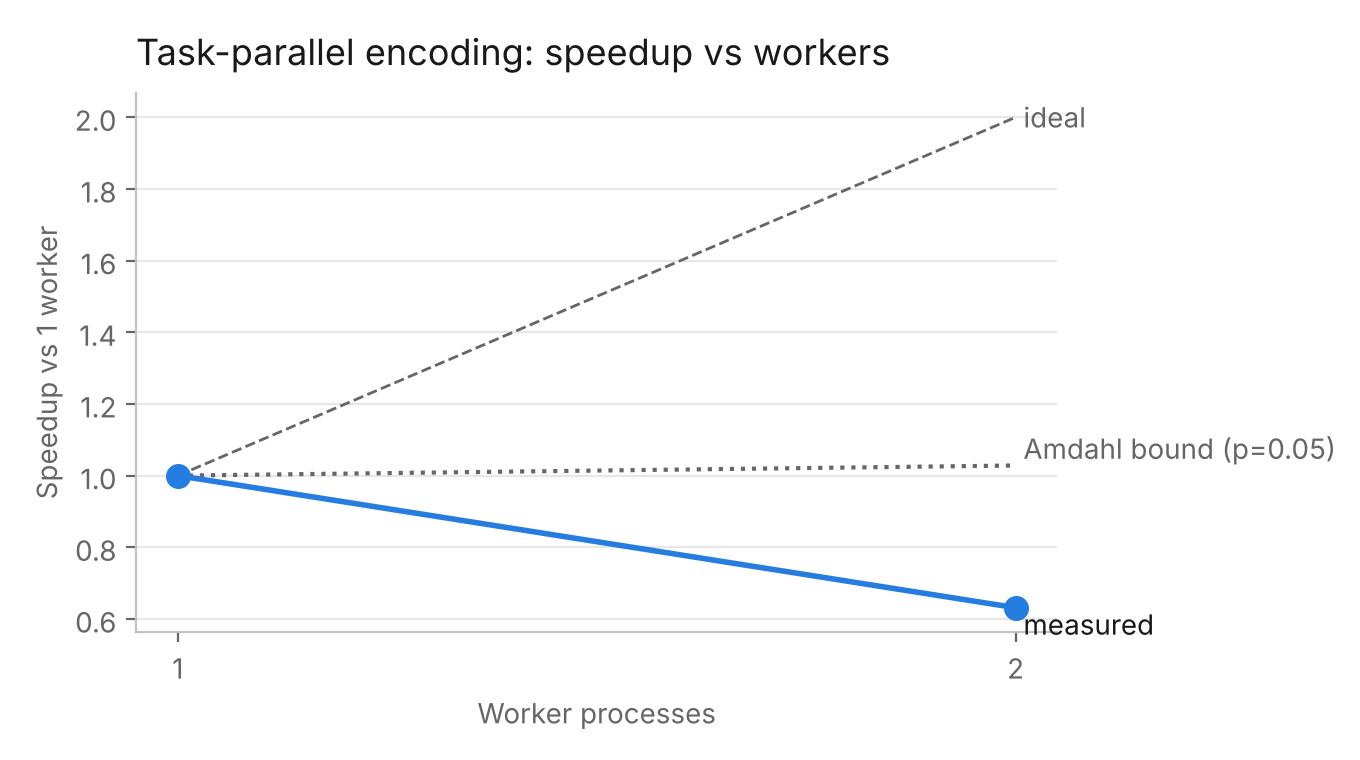

In [10]:
fig, ax = plt.subplots(figsize=(6.8, 3.8))
ax.plot(bench['workers'], bench['workers'], color=INK2, linewidth=1, linestyle='--')
ax.plot(amdahl['workers'], amdahl['amdahl_bound'], color=INK2, linewidth=1.5, linestyle=':')
ax.plot(bench['workers'], bench['speedup'], color=BLUE, linewidth=2, marker='o', markersize=8)
x = bench['workers'].iloc[-1]
ax.text(x, x, ' ideal', color=INK2, va='center')
ax.text(x, amdahl['amdahl_bound'].iloc[-1], f' Amdahl bound (p={p:.2f})', color=INK2, va='bottom')
ax.text(x, bench['speedup'].iloc[-1], ' measured', color=INK, va='top')
ax.set_xticks(bench['workers'])
style(ax, 'Task-parallel encoding: speedup vs workers', 'Worker processes', 'Speedup vs 1 worker')
save(fig, 'B_feature_speedup')

### 5.2 Load imbalance between tasks
Tasks are not equally expensive. Tables with more distinct keys (zone pair × time band) take longer. With few tasks per worker, the slowest task decides when the pool finishes.

In [11]:
fbt = FeatureBuilder(n_jobs=1); fbt.fit_transform(Xtr, ytr)
t = pd.DataFrame([(tag[1], sec) for tag, sec in fbt.task_seconds_], columns=['table', 'seconds'])
load = t.groupby('table')['seconds'].agg(['mean', 'max']).mul(1000).round(3).rename(columns=lambda c: f'{c}_ms')
imbalance = float(t['seconds'].max() / t['seconds'].mean())
summary['load_imbalance'] = {'max_over_mean_task_time': round(imbalance, 2), 'per_table_ms': load.to_dict()}
print(f'slowest task / mean task = {imbalance:.2f}x')
load

slowest task / mean task = 1.18x


,mean_ms,max_ms
table,,
te_dropoff,0.346,0.368
te_pair,0.386,0.422
te_pair_band,0.404,0.437
te_pickup,0.356,0.422
te_pickup_hour,0.369,0.415


**Interpretation:** the parallel fraction *p* is small. The encoding tasks are cheap after integer coding, while building calendar features and keys stays serial. Amdahl's law therefore caps the speedup close to 1×. The measured speedup falls even below that bound because each run pays process start-up and data-transfer costs, and the slowest tasks hold up the pool. On the full month, the task share grows with the data, but key preparation grows too. The next improvement would be to move key preparation into the per-table tasks.

## 6. Non-determinism: two real sources, evidence and fixes
For each source we run the **unfixed** version several times and show the output changes from run to run. We then run the **fixed** version and show the output is identical every time.

### 6.1 Source 1: unseeded random fold assignment (out-of-fold encoding)

In [12]:
unseeded = [fingerprint(FeatureBuilder(seed=None).fit_transform(Xtr, ytr)) for _ in range(3)]
seeded = [fingerprint(FeatureBuilder(seed=420720).fit_transform(Xtr, ytr)) for _ in range(3)]
a = FeatureBuilder(seed=None).fit_transform(Xtr, ytr); b = FeatureBuilder(seed=None).fit_transform(Xtr, ytr)
max_diff = float((a['te_pair'] - b['te_pair']).abs().max())
summary['nondeterminism_folds'] = {'unseeded_fingerprints': unseeded, 'seeded_fingerprints': seeded,
                                   'max_abs_diff_te_pair_unseeded': round(max_diff, 4)}
print('unseeded runs:', unseeded, '-> distinct:', len(set(unseeded)))
print('seeded runs:  ', seeded, '-> distinct:', len(set(seeded)))
print(f'largest change in one te_pair value between two unseeded runs: {max_diff:.4f} (log-minutes)')

unseeded runs: ['927575c849c85e19', '454cd9011efbb5cb', '5bab6817d29793db'] -> distinct: 3
seeded runs:   ['fddf67626a7ee693', 'fddf67626a7ee693', 'fddf67626a7ee693'] -> distinct: 1
largest change in one te_pair value between two unseeded runs: 0.2222 (log-minutes)


**Fix:** a fixed seed (`420720`) for the fold permutation. **Limit:** this makes runs repeatable, but a *different* seed still gives slightly different encodings. The result is reproducible, not seed-independent.

### 6.2 Source 2: hash-ordered category codes across processes
A tempting way to encode zones as category codes is `{zone: i for i, zone in enumerate(set(zones))}`. Python randomises string hashing **per process** (`PYTHONHASHSEED`), so set order, and therefore every zone's code, changes in each new process. That includes each worker in a process pool. We run the same script in 3 fresh processes:

In [13]:
import subprocess
env = {k: v for k, v in os.environ.items() if k != 'PYTHONHASHSEED'}   # default: random per process
rows = []
for run in range(1, 4):
    out = subprocess.run([sys.executable, 'nondeterminism_hash_demo.py', DATA], capture_output=True,
                         text=True, env=env, check=True).stdout.strip().split(',')
    rows.append({'run': run, 'naive: code of JFK (132)': int(out[0]), 'naive: hash of all codes': out[1],
                 'fixed: code of JFK (132)': int(out[2]), 'fixed: hash of all codes': out[3]})
hash_demo = pd.DataFrame(rows)
summary['nondeterminism_hash'] = hash_demo.to_dict('records')
hash_demo

,run,naive: code of JFK (132),naive: hash of all codes,fixed: code of JFK (132),fixed: hash of all codes
0,1,157,be25c42f63c0,131,371c98dfa459
1,2,147,888575c7e23d,131,371c98dfa459
2,3,82,9d18519c3324,131,371c98dfa459


**Fix:** codes come from a **fixed, sorted vocabulary** of TLC zone IDs (`ZONE_VOCAB`), and the learned tables use `pd.factorize(sort=True)`. The same zone gets the same code in every process and on every machine. **Limit:** zones outside the vocabulary all map to one `__OTHER__` code.

**Prevented by design (a third source):** recombining parallel results in *completion* order (`as_completed`) would make the column order and the fold assembly depend on scheduling. We use `pool.map`, which returns results in submission order, and assemble by task tag. The hash checks in Section 5 confirm identical output for every worker count.

## 6. Export for Parts C/D

In [14]:
for name, F, X, y in [('train', F_tr, Xtr, ytr), ('validation', F_va, Xva, yva), ('test', F_te, Xte, yte)]:
    F.assign(duration_minutes=y.values, pickup_datetime=pd.to_datetime(X['pickup_datetime']).values
             ).to_parquet(OUT / f'features_{name}.parquet', index=False)
summary['feature_fingerprints'] = {'train': fingerprint(F_tr), 'validation': fingerprint(F_va), 'test': fingerprint(F_te)}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2, default=str))
print('Saved to', OUT); sorted(p.name for p in OUT.iterdir())

Saved to outputs/local_sample


['benchmark_features.csv',
 'feature_signal_validation.csv',
 'features_test.parquet',
 'features_train.parquet',
 'features_validation.parquet',
 'figures',
 'summary.json']

## 7. Summary of Part B

In [15]:
t, v, b = summary['target_train'], summary['validation_sanity'], pd.DataFrame(summary['benchmark'])
grp = {r['group']: r['median'] for r in summary['trip_groups_train']}
best = b.loc[b['speedup'].idxmax()]
par_text = (f"best speedup {best['speedup']:.2f}× at {int(best['workers'])} workers" if best['workers'] > 1
            else f"no speedup at this input size ({b['speedup'].iloc[-1]:.2f}× at {int(b['workers'].iloc[-1])} workers: overhead dominates)")
display(Markdown(f"""
- **Data:** {summary['rows']['all']:,} cleaned trips → train {summary['rows']['train']:,} / validation {summary['rows']['validation']:,} / test {summary['rows']['test']:,} (chronological).
- **Target:** median {t['50%']} min, mean {t['mean']} min, skew {t['skew']} → modelled as log1p(duration).
- **Location dominates:** to airport {grp.get('To airport')} min, from airport {grp.get('From airport')} min, other {grp.get('Other trips')} min, same zone {grp.get('Same pickup & dropoff zone')} min (medians).
- **Time effect:** hour × weekday medians range {summary['hour_weekday_median_range'][0]}–{summary['hour_weekday_median_range'][1]} min.
- **Features:** {summary['n_features']} numeric features; all learned statistics fitted on train only (out-of-fold for training rows).
- **Signal check:** zone-pair lookup MAE {v['MAE_zone_pair_lookup']} min vs {v['MAE_constant_train_median']} min for a constant baseline ({v['reduction_pct']}% lower).
- **Task parallelism:** {par_text}; outputs identical across all runs and worker counts: **{bool(b['all_outputs_equal'].all())}**. Parallel fraction p = {summary['amdahl']['parallel_fraction_p']} → Amdahl bound {summary['amdahl']['max_speedup_infinite_workers']}× with infinite workers; slowest task {summary['load_imbalance']['max_over_mean_task_time']}× the mean task.
- **Non-determinism:** (1) unseeded folds gave {len(set(summary['nondeterminism_folds']['unseeded_fingerprints']))} different outputs in 3 runs → fixed seed gives {len(set(summary['nondeterminism_folds']['seeded_fingerprints']))}; (2) set-based zone codes gave {hash_demo['naive: hash of all codes'].nunique()} different encodings in 3 processes → fixed sorted vocabulary gives {hash_demo['fixed: hash of all codes'].nunique()}.
"""))


- **Data:** 100,000 cleaned trips → train 67,074 / validation 14,415 / test 18,511 (chronological).
- **Target:** median 13.08 min, mean 16.67 min, skew 2.66 → modelled as log1p(duration).
- **Location dominates:** to airport 33.44 min, from airport 32.62 min, other 12.62 min, same zone 4.62 min (medians).
- **Time effect:** hour × weekday medians range 10.0–17.8 min.
- **Features:** 33 numeric features; all learned statistics fitted on train only (out-of-fold for training rows).
- **Signal check:** zone-pair lookup MAE 6.15 min vs 8.04 min for a constant baseline (23.6% lower).
- **Task parallelism:** no speedup at this input size (0.63× at 2 workers: overhead dominates); outputs identical across all runs and worker counts: **True**. Parallel fraction p = 0.055 → Amdahl bound 1.06× with infinite workers; slowest task 1.18× the mean task.
- **Non-determinism:** (1) unseeded folds gave 3 different outputs in 3 runs → fixed seed gives 1; (2) set-based zone codes gave 3 different encodings in 3 processes → fixed sorted vocabulary gives 1.
